In [1]:
from langgraph.graph import StateGraph
from typing import Dict, Any
from IPython.display import Image, display

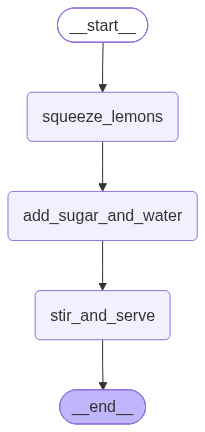

In [2]:

# Define nodes
def squeeze_lemons(state: Dict[str, Any]) -> Dict[str, Any]:
    state["juice"] = f"Juice from {state.get('lemons', 0)} lemons"
    return state

def add_sugar_and_water(state: Dict[str, Any]) -> Dict[str, Any]:
    state["mix"] = f"{state['juice']} + {state.get('sugar', 0)} spoons sugar + {state.get('water', '')} water"
    return state

def stir_and_serve(state: Dict[str, Any]) -> Dict[str, Any]:
    state["final"] = f"{state['mix']} → Stirred and ready to serve!"
    return state

from typing import TypedDict

class LemonState(TypedDict):
    lemons: int
    sugar: int
    water: str
    juice: str
    mix: str
    final: str


# Build graph
builder = StateGraph(LemonState)
builder.add_node("squeeze_lemons", squeeze_lemons)
builder.add_node("add_sugar_and_water", add_sugar_and_water)
builder.add_node("stir_and_serve", stir_and_serve)

builder.set_entry_point("squeeze_lemons")
builder.add_edge("squeeze_lemons", "add_sugar_and_water")
builder.add_edge("add_sugar_and_water", "stir_and_serve")
builder.set_finish_point("stir_and_serve")

graph = builder.compile()

# ✅ Visualize as Mermaid PNG
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Visualization failed. Ensure Mermaid & pygraphviz dependencies are installed.")
    print(f"Error: {e}")

In [3]:
# Initial input state
initial_state: LemonState = {
    "lemons": 8,
    "sugar": 6,
    "water": "2 glass",
    "juice": "",
    "mix": "",
    "final": ""
}

# Run the LangGraph
result = graph.invoke(initial_state)

# Print final result
print("🧃 Final Output:", result["final"])


🧃 Final Output: Juice from 8 lemons + 6 spoons sugar + 2 glass water → Stirred and ready to serve!


In [4]:
# Define State
class BlogState(TypedDict):
    topic: str
    research_notes: str
    draft: str
    final_post: str

--- Researching Topic ---
--- Writing Draft ---
--- Proofreading & Publishing ---

--- Final Output ---
topic: Artificial Intelligence in 2026
research_notes: Key facts and insights collected on: Artificial Intelligence in 2026
draft: Draft Article based on -> Key facts and insights collected on: Artificial Intelligence in 2026
final_post: Draft Article based on -> Key facts and insights collected on: Artificial Intelligence in 2026 
[Status: Proofread, formatted with headings, and ready to publish!]


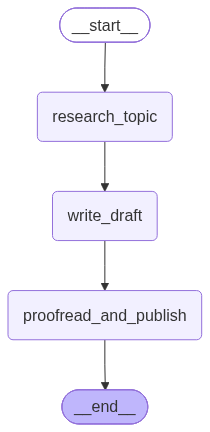

In [5]:
# Define Nodes
def research_topic(state: BlogState) -> BlogState:
    print("--- Researching Topic ---")
    topic = state.get("topic", "General")
    state["research_notes"] = f"Key facts and insights collected on: {topic}"
    return state

def write_draft(state: BlogState) -> BlogState:
    print("--- Writing Draft ---")
    state["draft"] = f"Draft Article based on -> {state['research_notes']}"
    return state

def proofread_and_publish(state: BlogState) -> BlogState:
    print("--- Proofreading & Publishing ---")
    state["final_post"] = f"{state['draft']} \n[Status: Proofread, formatted with headings, and ready to publish!]"
    return state

# Build Graph
builder = StateGraph(BlogState)

# Add Nodes
builder.add_node("research_topic", research_topic)
builder.add_node("write_draft", write_draft)
builder.add_node("proofread_and_publish", proofread_and_publish)

# Add Edges (Flow)
builder.set_entry_point("research_topic")
builder.add_edge("research_topic", "write_draft")
builder.add_edge("write_draft", "proofread_and_publish")
builder.set_finish_point("proofread_and_publish")

# Compile Graph
graph = builder.compile()

# Test the graph by running it
initial_state = {
    "topic": "Artificial Intelligence in 2026",
    "research_notes": "",
    "draft": "",
    "final_post": ""
}

result = graph.invoke(initial_state)
print("\n--- Final Output ---")
for key, value in result.items():
    print(f"{key}: {value}")

# Visualize as Mermaid PNG (If running in Jupyter Notebook)
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("\nVisualization note: Mermaid display works inside Jupyter Notebooks.")